# Opioid Prescribing Patterns & Intervention Targeting
### Medicare Part D prescribers, 2013–2016 (CMS public data)

**Business question (framed like a client engagement):**
A state health department wants to reduce risky opioid prescribing. It has a small team that can visit doctors
for one-on-one education ("academic detailing"). Before spending the budget, it wants to know:

1. **Where is opioid prescribing concentrated?** (which doctors, specialties, regions)
2. **Are the differences real or just noise?** (hypothesis tests)
3. **Which factors explain a doctor's opioid prescribing rate, and by how much?** (explanatory regression)
4. **Which doctors should the team visit to get the biggest reduction, within its limits?** (optimization with PuLP)

**Methods:** descriptive statistics, Pareto analysis, Kruskal–Wallis, Mann–Whitney U, chi-square test,
Wilcoxon signed-rank (paired), confidence intervals, effect sizes, OLS regression with robust standard errors,
VIF, and integer linear programming. No machine learning is used. Regression is used to *explain*, not to *predict*.

## 0. Setup
Data: *Medicare Part D Opioid Prescriber Summary File* (CMS), one row per prescriber per year.
Key columns: specialty, state, ZIP, total claims (prescriptions), opioid claims, opioid prescribing rate
(= opioid claims ÷ total claims × 100).

In [35]:
import warnings; warnings.filterwarnings("ignore")
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_DIR = "../data"          # put the CMS CSVs here (see data/README.md)
FIG_DIR, RES_DIR = "../figures", "../results"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

# chart style: one accent colour, quiet axes
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#b4b2aa", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

COLS = {"NPI": "npi", "NPPES Provider State": "state", "NPPES Provider ZIP Code": "zip",
        "Specialty Description": "specialty", "Total Claim Count": "total_claims",
        "Opioid Claim Count": "opioid_claims", "Opioid Prescribing Rate": "opioid_rate"}

def load(year):
    path = f"{DATA_DIR}/medicare-part-d-opioid-prescriber-summary-file-{year}.csv"
    # column names vary slightly by year (e.g. "Zip" vs "ZIP"), so match them case-insensitively
    header = pd.read_csv(path, nrows=0).columns
    lookup = {k.lower(): v for k, v in COLS.items()}
    use = {c: lookup[c.lower()] for c in header if c.lower() in lookup}
    zip_col = [c for c, v in use.items() if v == "zip"][0]
    df = pd.read_csv(path, usecols=list(use), dtype={zip_col: str}).rename(columns=use)
    df["year"] = year
    return df

raw = {y: load(y) for y in [2013, 2014, 2015, 2016]}
for y, d in raw.items():
    print(y, f"{len(d):,} prescribers")

2013 1,049,299 prescribers
2014 1,072,978 prescribers
2015 1,102,253 prescribers
2016 1,131,550 prescribers


## 1. Data cleaning

**Important data limitation:** CMS hides (suppresses) opioid counts between 1 and 10 to protect patient privacy.
Those rows have a blank opioid rate, so we can't use them. I keep only rows with a known opioid rate,
and only the 50 states + DC (dropping territories and military codes).

*Interview point:* this means the analysis describes prescribers with either zero or 11+ opioid claims.
Low-volume opioid prescribers are under-represented, which slightly overstates typical rates.

In [36]:
US = set("AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY "
         "NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY".split())
REGION = {**dict.fromkeys("CT ME MA NH RI VT NJ NY PA".split(), "Northeast"),
          **dict.fromkeys("IL IN MI OH WI IA KS MN MO NE ND SD".split(), "Midwest"),
          **dict.fromkeys("DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX".split(), "South"),
          **dict.fromkeys("AZ CO ID MT NV NM UT WY AK CA HI OR WA".split(), "West")}

def clean(d):
    n0 = len(d)
    suppressed = d["opioid_rate"].isna().mean()
    d = d[d["state"].isin(US)].dropna(subset=["opioid_rate"]).copy()
    d["region"] = d["state"].map(REGION)
    d["zip3"] = d["zip"].str[:3]
    return d, n0, suppressed

clean_data, cleaning_log = {}, []
for y, d in raw.items():
    c, n0, sup = clean(d)
    clean_data[y] = c
    cleaning_log.append({"year": y, "raw_rows": n0, "suppressed_share": round(sup, 3), "rows_used": len(c)})
pd.DataFrame(cleaning_log)

,year,raw_rows,suppressed_share,rows_used
0,2013,1049299,0.304,722281
1,2014,1072978,0.297,745820
2,2015,1102253,0.285,780332
3,2016,1131550,0.282,804678


In [37]:
df = clean_data[2016]          # main analysis year
df.describe()[["total_claims", "opioid_claims", "opioid_rate"]].round(1)

,total_claims,opioid_claims,opioid_rate
count,804678.0,804678.0,804678.0
mean,1608.6,96.1,11.0
std,3551.8,315.0,17.4
min,11.0,0.0,0.0
25%,72.0,0.0,0.0
50%,273.0,19.0,2.9
75%,1437.0,69.0,14.3
max,324209.0,21767.0,100.0


**Reading this table:** the mean opioid rate is well above the median, so the distribution is **right-skewed**
(a few doctors with very high rates pull the mean up). That is why I use **non-parametric tests**
(they compare medians/ranks and don't assume a normal distribution) in Section 3.

## 2. Exploratory analysis

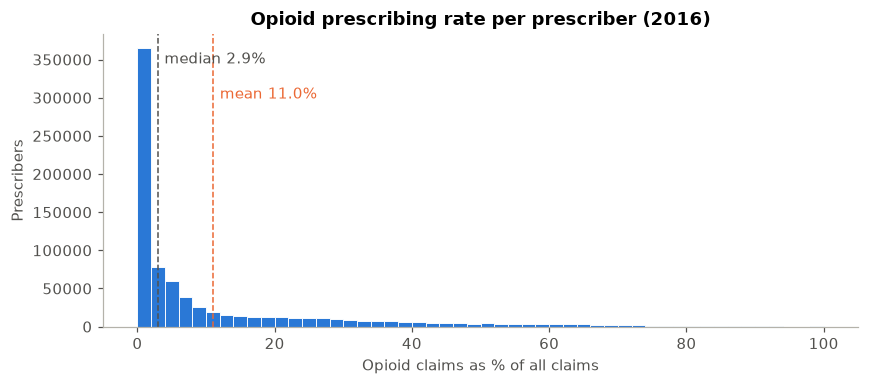

In [38]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df["opioid_rate"], bins=50, color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(df["opioid_rate"].median(), color=INK, ls="--", lw=1)
ax.axvline(df["opioid_rate"].mean(), color=ORANGE, ls="--", lw=1)
ax.text(df["opioid_rate"].median()+1, ax.get_ylim()[1]*0.9, f"median {df['opioid_rate'].median():.1f}%", color=INK)
ax.text(df["opioid_rate"].mean()+1, ax.get_ylim()[1]*0.78, f"mean {df['opioid_rate'].mean():.1f}%", color=ORANGE)
ax.set(title="Opioid prescribing rate per prescriber (2016)", xlabel="Opioid claims as % of all claims", ylabel="Prescribers")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_rate_distribution.png"); plt.show()

### 2.1 Pareto analysis: how concentrated is opioid prescribing?
If a small share of doctors writes most opioid prescriptions, targeting them is efficient.

top 1pct share: 24.7% of all opioid claims
top 5pct share: 53.0% of all opioid claims
top 10pct share: 69.0% of all opioid claims
top 20pct share: 84.3% of all opioid claims


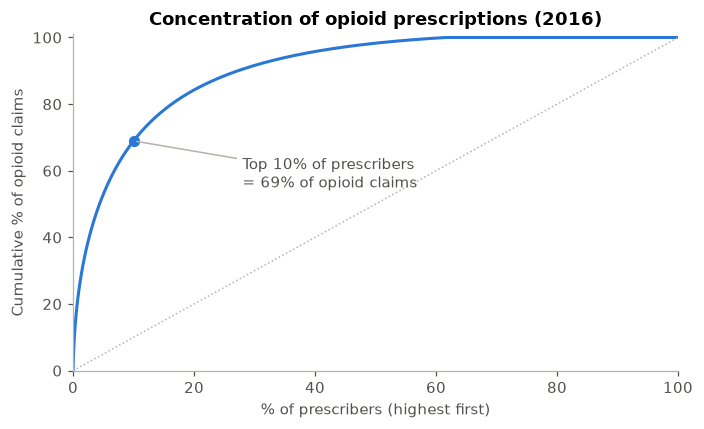

In [39]:
s = df["opioid_claims"].sort_values(ascending=False).to_numpy()
cum = s.cumsum() / s.sum()
pct = np.arange(1, len(s)+1) / len(s)
pareto = {f"top_{int(p*100)}pct_share": float(cum[int(p*len(s))-1]) for p in [0.01, 0.05, 0.10, 0.20]}
for k, v in pareto.items(): print(f"{k.replace('_',' ')}: {v:.1%} of all opioid claims")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(pct*100, cum*100, color=BLUE, lw=2)
ax.plot([0,100],[0,100], color=GREY, lw=1, ls=":")
ax.scatter([10], [pareto["top_10pct_share"]*100], color=BLUE, s=40, zorder=3)
ax.annotate(f"Top 10% of prescribers\n= {pareto['top_10pct_share']:.0%} of opioid claims",
            (10, pareto["top_10pct_share"]*100), xytext=(28, 55), color=INK, arrowprops=dict(arrowstyle="-", color=GREY))
ax.set(title="Concentration of opioid prescriptions (2016)", xlabel="% of prescribers (highest first)",
       ylabel="Cumulative % of opioid claims", xlim=(0,100), ylim=(0,101))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_pareto.png"); plt.show()

### 2.2 Which specialties prescribe the most opioids?

In [40]:
spec = (df.groupby("specialty")
          .agg(prescribers=("npi", "size"), opioid_claims=("opioid_claims", "sum"),
               total_claims=("total_claims", "sum"), median_rate=("opioid_rate", "median"))
          .assign(share_of_all_opioid_claims=lambda t: t.opioid_claims / t.opioid_claims.sum())
          .sort_values("opioid_claims", ascending=False))
top_spec = spec.head(10)
top_spec[["prescribers", "opioid_claims", "share_of_all_opioid_claims", "median_rate"]].round(3)

,prescribers,opioid_claims,share_of_all_opioid_claims,median_rate
specialty,,,,
Family Practice,92781,19735976.0,0.255,3.952
Internal Medicine,102109,16522764.0,0.214,3.213
Nurse Practitioner,105051,7682112.0,0.099,1.035
Physician Assistant,66075,5438162.0,0.070,6.250
Physical Medicine and Rehabilitation,6732,3143983.0,0.041,30.000
Orthopedic Surgery,19691,3054304.0,0.039,47.393
Anesthesiology,5806,2898230.0,0.037,24.244
Interventional Pain Management,1626,2412784.0,0.031,56.766
Pain Management,2062,2410504.0,0.031,54.167


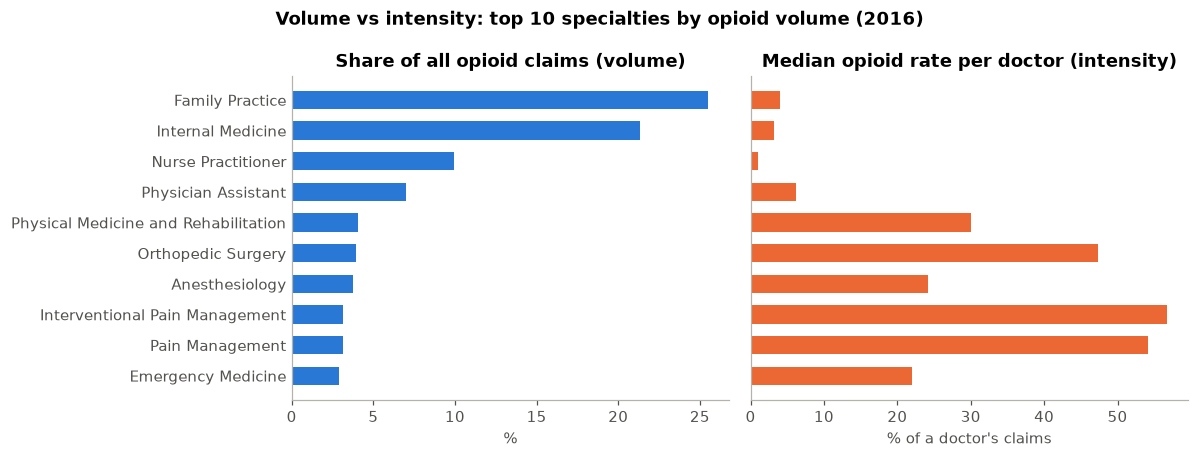

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
t = top_spec.iloc[::-1]
axes[0].barh(t.index, t["share_of_all_opioid_claims"]*100, color=BLUE, height=0.6)
axes[0].set(title="Share of all opioid claims (volume)", xlabel="%")
axes[1].barh(t.index, t["median_rate"], color=ORANGE, height=0.6)
axes[1].set(title="Median opioid rate per doctor (intensity)", xlabel="% of a doctor's claims")
for ax in axes: ax.tick_params(axis="y", length=0)
plt.suptitle("Volume vs intensity: top 10 specialties by opioid volume (2016)", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_specialties.png"); plt.show()

**Key insight (volume vs intensity):** primary care (Family Practice, Internal Medicine) writes the largest
*number* of opioid prescriptions simply because there are so many of them, but each doctor has a *low* rate.
Pain specialists have very *high* rates but are few in number. A good intervention has to account for both,
which is exactly what the optimization in Section 5 does.

### 2.3 Trend over time: did opioid prescribing fall from 2013 to 2016?

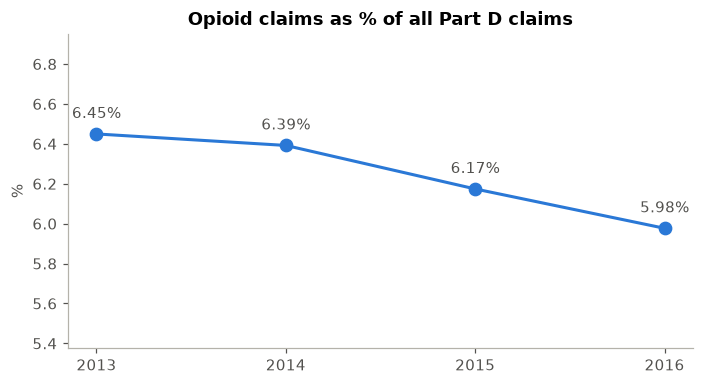

,year,opioid_claims,total_claims,median_rate,aggregate_rate
0,2013,77849446.0,1207058062,4.353,6.450
1,2014,79371415.0,1241745226,4.090,6.392
2,2015,78051171.0,1264216297,3.400,6.174
3,2016,77363124.0,1294406244,2.932,5.977


In [42]:
trend = pd.DataFrame([{"year": y, "opioid_claims": d["opioid_claims"].sum(), "total_claims": d["total_claims"].sum(),
                       "median_rate": d["opioid_rate"].median()} for y, d in clean_data.items()])
trend["aggregate_rate"] = trend["opioid_claims"] / trend["total_claims"] * 100
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(trend["year"], trend["aggregate_rate"], color=BLUE, lw=2, marker="o", ms=8)
for x, yv in zip(trend["year"], trend["aggregate_rate"]): ax.text(x, yv+0.08, f"{yv:.2f}%", ha="center", color=INK)
ax.set(title="Opioid claims as % of all Part D claims", xlabel="", ylabel="%", xticks=trend["year"],
       ylim=(trend["aggregate_rate"].min()-0.6, trend["aggregate_rate"].max()+0.5))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_trend.png"); plt.show()
trend.round(3)

## 3. Hypothesis testing
Each test follows the same structure: **question → H₀/H₁ → test choice and why → result → effect size → business meaning.**

Significance level α = 0.05.

**A note on huge samples:** with hundreds of thousands of doctors, almost *any* difference is statistically
significant. So for every test I also report an **effect size**, which says whether the difference is big enough to matter.

### Test 1: Do opioid prescribing rates differ across specialties?
- **H₀:** the distribution of opioid rates is the same for all top-10 specialties
- **H₁:** at least one specialty differs
- **Test:** Kruskal–Wallis H test (non-parametric alternative to one-way ANOVA; chosen because rates are skewed, not normal)
- **Effect size:** epsilon² (ε²): ~0.01 small, ~0.08 medium, ≥0.26 large

In [43]:
groups = [df.loc[df.specialty == s, "opioid_rate"] for s in top_spec.index]
H, p_kw = stats.kruskal(*groups)
n_kw = sum(len(g) for g in groups)
eps2 = (H - len(groups) + 1) / (n_kw - len(groups))
print(f"H = {H:,.0f}, p = {p_kw:.2e}, epsilon² = {eps2:.3f}  (n = {n_kw:,})")

H = 117,691, p = 0.00e+00, epsilon² = 0.268  (n = 439,907)


### Test 2: Do nurse practitioners prescribe opioids at a different rate than primary-care physicians?
A real policy question: several US states were expanding NP prescribing authority during this period.
- **H₀:** NP opioid rates and primary-care physician (Family Practice + Internal Medicine) rates come from the same distribution
- **H₁:** they differ
- **Test:** Mann–Whitney U (non-parametric two-group comparison)
- **Effect size:** rank-biserial correlation r (−1 to +1; |r| ≈ 0.1 small, 0.3 medium, 0.5 large)
- **Plus:** a 95% bootstrap confidence interval for the difference in medians

In [44]:
np_rates = df.loc[df.specialty == "Nurse Practitioner", "opioid_rate"].to_numpy()
pcp_rates = df.loc[df.specialty.isin(["Family Practice", "Internal Medicine"]), "opioid_rate"].to_numpy()
U, p_mw = stats.mannwhitneyu(np_rates, pcp_rates, alternative="two-sided")
r_rb = 1 - 2*U / (len(np_rates)*len(pcp_rates))     # positive => PCPs tend to have higher rates
rng = np.random.default_rng(42)
boot = [np.median(rng.choice(np_rates, 5000)) - np.median(rng.choice(pcp_rates, 5000)) for _ in range(1000)]
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
med_diff = np.median(np_rates) - np.median(pcp_rates)
print(f"Median NP = {np.median(np_rates):.2f}%, median PCP = {np.median(pcp_rates):.2f}%")
print(f"U = {U:,.0f}, p = {p_mw:.2e}, rank-biserial r = {r_rb:.3f}")
print(f"Difference in medians (NP − PCP) = {med_diff:.2f} pts, 95% bootstrap CI [{ci_lo:.2f}, {ci_hi:.2f}]")

Median NP = 1.03%, median PCP = 3.60%
U = 8,369,675,654, p = 0.00e+00, rank-biserial r = 0.182
Difference in medians (NP − PCP) = -2.57 pts, 95% bootstrap CI [-2.99, -2.22]


### Test 3: Is the share of "high prescribers" independent of US region?
Define a **high prescriber** as a doctor whose opioid rate is in the top 10% nationally (2016).
- **H₀:** being a high prescriber is independent of region
- **H₁:** the share of high prescribers depends on region
- **Test:** chi-square test of independence on a region × high/not-high table
- **Effect size:** Cramér's V (0.1 small, 0.3 medium, 0.5 large)

In [45]:
p90 = df["opioid_rate"].quantile(0.90)
df["high_prescriber"] = df["opioid_rate"] > p90
table = pd.crosstab(df["region"], df["high_prescriber"])
chi2, p_chi, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
region_share = df.groupby("region")["high_prescriber"].mean().sort_values(ascending=False)
print(f"High-prescriber threshold (90th percentile) = {p90:.1f}%")
print(f"chi² = {chi2:,.0f}, dof = {dof}, p = {p_chi:.2e}, Cramér's V = {cramers_v:.3f}")
(region_share*100).round(1).rename("% high prescribers")

High-prescriber threshold (90th percentile) = 36.7%
chi² = 830, dof = 3, p = 1.37e-179, Cramér's V = 0.032


region
Midwest      10.8
South        10.5
West         10.2
Northeast     8.2
Name: % high prescribers, dtype: float64

### Test 4: Did the *same* doctors reduce their opioid rate between 2013 and 2016?
Comparing two separate years' averages is misleading because new doctors enter and others leave.
So I match each doctor to themselves (same NPI in both years): a **paired** design.
- **H₀:** the median within-doctor change in opioid rate is zero
- **H₁:** it is not zero
- **Test:** Wilcoxon signed-rank test (non-parametric paired test)
- **Plus:** 95% confidence interval for the mean change (paired t-interval; valid here by the Central Limit Theorem with this sample size)

In [46]:
paired = clean_data[2013][["npi", "opioid_rate"]].merge(clean_data[2016][["npi", "opioid_rate"]],
                                                        on="npi", suffixes=("_2013", "_2016"))
paired["change"] = paired["opioid_rate_2016"] - paired["opioid_rate_2013"]
W, p_w = stats.wilcoxon(paired["change"])
mean_chg = paired["change"].mean()
se = paired["change"].std(ddof=1) / np.sqrt(len(paired))
t_lo, t_hi = stats.t.interval(0.95, len(paired)-1, loc=mean_chg, scale=se)
share_down = (paired["change"] < 0).mean()
print(f"Doctors matched in both years: {len(paired):,}")
print(f"Mean change = {mean_chg:.2f} pts, 95% CI [{t_lo:.2f}, {t_hi:.2f}];  median change = {paired['change'].median():.2f}")
print(f"{share_down:.1%} of doctors reduced their rate.  Wilcoxon W = {W:,.0f}, p = {p_w:.2e}")

Doctors matched in both years: 525,852
Mean change = -1.40 pts, 95% CI [-1.43, -1.38];  median change = -0.00
50.0% of doctors reduced their rate.  Wilcoxon W = 27,295,308,192, p = 0.00e+00


In [47]:
tests = pd.DataFrame([
    ["Specialties differ (top 10)", "Kruskal–Wallis", p_kw, f"ε² = {eps2:.3f}"],
    ["NP vs primary-care physicians", "Mann–Whitney U", p_mw, f"r = {r_rb:.3f}; median diff {med_diff:.2f} pts"],
    ["High prescribers vs region", "Chi-square", p_chi, f"Cramér's V = {cramers_v:.3f}"],
    ["Same doctors, 2013→2016", "Wilcoxon signed-rank", p_w, f"mean change {mean_chg:.2f} pts"],
], columns=["Question", "Test", "p-value", "Effect size"])
tests["Reject H₀ (α=0.05)?"] = np.where(tests["p-value"] < 0.05, "Yes", "No")
tests

,Question,Test,p-value,Effect size,Reject H₀ (α=0.05)?
0,Specialties differ (top 10),Kruskal–Wallis,0.000000e+00,ε² = 0.268,Yes
1,NP vs primary-care physicians,Mann–Whitney U,0.000000e+00,r = 0.182; median diff -2.57 pts,Yes
2,High prescribers vs region,Chi-square,1.369126e-179,Cramér's V = 0.032,Yes
3,"Same doctors, 2013→2016",Wilcoxon signed-rank,0.000000e+00,mean change -1.40 pts,Yes


**How to read these together:** all four are statistically significant (expected with this much data), but the
effect sizes tell the real story. Specialty has a **large** effect on opioid rates, while region has only a
**small** effect. So specialty matters far more than geography when deciding whom to target.

## 4. Explanatory regression (OLS)
**Question:** holding other factors constant, how much does each factor change a doctor's opioid rate?

**Model:** `opioid_rate ~ specialty + log(total_claims) + region`
- `specialty`: top-12 specialties by opioid volume, all others grouped as "Other". Reference group = **Family Practice**, so each specialty coefficient means "percentage points above/below a Family Practice doctor, all else equal."
- `log(total_claims)`: practice size. I use the log because claim counts are extremely skewed; a coefficient *b* means a doctor with **double** the claims has a rate about *b* × ln(2) ≈ 0.69*b* points different.
- `region`: reference = Northeast.
- **Robust (HC3) standard errors**, because the spread of residuals is not constant (heteroskedasticity).

This is **inference, not prediction**: no train/test split, because the goal is to understand drivers.

In [48]:
reg_specs = spec.head(12).index
reg = df.copy()
reg["spec_grp"] = np.where(reg["specialty"].isin(reg_specs), reg["specialty"], "Other")
reg["log_claims"] = np.log(reg["total_claims"])
model = smf.ols("opioid_rate ~ C(spec_grp, Treatment('Family Practice')) + log_claims + C(region, Treatment('Northeast'))",
                data=reg).fit(cov_type="HC3")
print(f"n = {int(model.nobs):,},  R² = {model.rsquared:.3f},  adj. R² = {model.rsquared_adj:.3f}")
coef = pd.DataFrame({"coef": model.params, "ci_low": model.conf_int()[0], "ci_high": model.conf_int()[1], "p": model.pvalues})
coef.index = (coef.index.str.replace(r"C\(spec_grp, Treatment\('Family Practice'\)\)\[T\.", "Specialty: ", regex=True)
                        .str.replace(r"C\(region, Treatment\('Northeast'\)\)\[T\.", "Region: ", regex=True).str.replace("]", ""))
coef.round(3)

n = 804,678,  R² = 0.230,  adj. R² = 0.230


,coef,ci_low,ci_high,p
Intercept,6.578,6.414,6.742,0.0
Specialty: Anesthesiology,22.789,22.009,23.569,0.0
Specialty: Dentist,9.190,9.038,9.343,0.0
Specialty: Emergency Medicine,15.177,15.061,15.294,0.0
Specialty: Internal Medicine,-0.683,-0.740,-0.626,0.0
Specialty: Interventional Pain Management,47.599,46.662,48.535,0.0
Specialty: Nurse Practitioner,1.737,1.634,1.840,0.0
Specialty: Orthopedic Surgery,41.049,40.794,41.304,0.0
Specialty: Other,2.789,2.712,2.865,0.0
Specialty: Pain Management,45.505,44.689,46.320,0.0


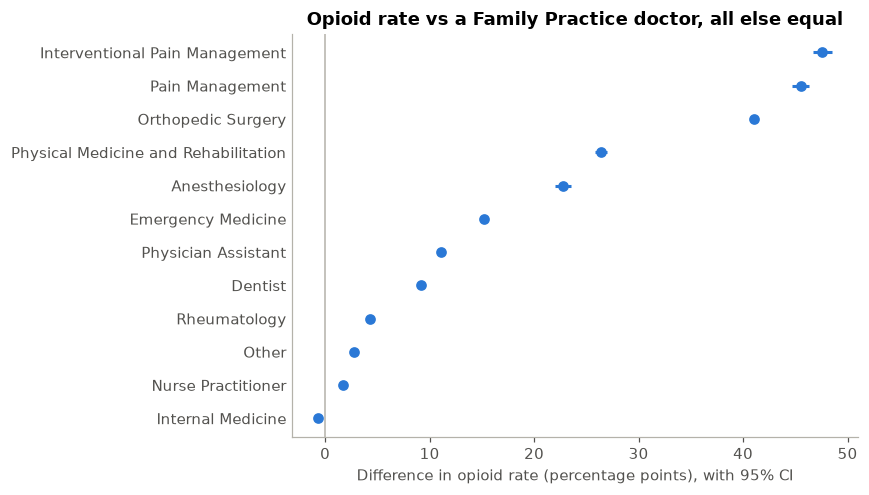

In [49]:
c = coef[coef.index.str.startswith("Specialty")].sort_values("coef")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axvline(0, color=GREY, lw=1)
ax.errorbar(c["coef"], c.index.str.replace("Specialty: ", ""), xerr=[c["coef"]-c["ci_low"], c["ci_high"]-c["coef"]],
            fmt="o", color=BLUE, ms=6, capsize=0, elinewidth=2)
ax.set(title="Opioid rate vs a Family Practice doctor, all else equal",
       xlabel="Difference in opioid rate (percentage points), with 95% CI")
ax.tick_params(axis="y", length=0)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_regression_coefficients.png"); plt.show()

### 4.1 Checking the model's assumptions
1. **Multicollinearity (VIF):** are any predictors basically duplicates of each other? VIF > 5–10 is a warning sign.
2. **Residuals:** plot residuals against fitted values. Ideally a shapeless cloud around zero.

Max VIF = 3.06  (C(spec_grp, Treatment('Family Practice'))[T.Other])


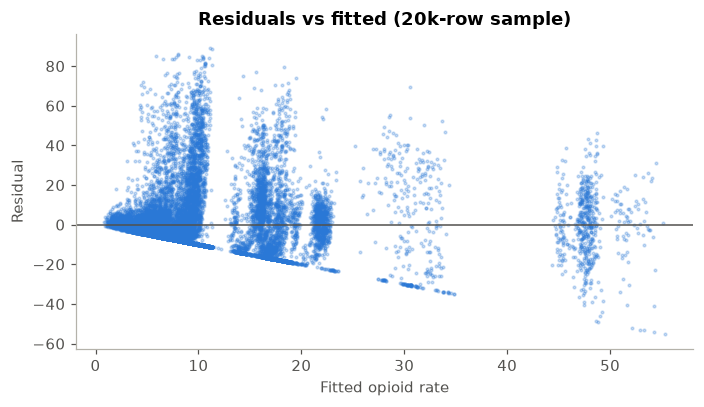

In [50]:
X = pd.DataFrame(model.model.exog, columns=model.model.exog_names).drop(columns="Intercept")
# VIF on a 50k random sample of rows (identical in expectation, much faster)
Xs = X.sample(50_000, random_state=1)
Xs.insert(0, "const", 1.0)
vif = pd.Series([variance_inflation_factor(Xs.values, i) for i in range(1, Xs.shape[1])], index=X.columns, name="VIF")
print(f"Max VIF = {vif.max():.2f}  ({vif.idxmax()[:60]})")

samp = np.random.default_rng(0).choice(len(model.resid), 20_000, replace=False)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(model.fittedvalues.iloc[samp], model.resid.iloc[samp], s=3, alpha=0.25, color=BLUE)
ax.axhline(0, color=INK, lw=1)
ax.set(title="Residuals vs fitted (20k-row sample)", xlabel="Fitted opioid rate", ylabel="Residual")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_residuals.png"); plt.show()

**Honest interpretation of the diagnostics:**
- VIFs are low, so the specialty, size and region effects are separately identifiable.
- The residual plot shows **diagonal bands and a floor**: the opioid rate cannot go below 0 or above 100,
  and many doctors sit at exactly 0. This means a straight-line model is an **approximation**. The coefficient
  *directions and rough sizes* are trustworthy (and match the non-parametric tests), but exact numbers shouldn't be over-read.
  A natural next step would be a fractional/beta regression or a two-part model (does a doctor prescribe any opioids? if so, how many?).
- R² tells us how much of the variation these few variables explain; the rest comes from things not in the data
  (patient mix, training, local policy).

## 5. Decision analytics: whom should the education team visit? (PuLP)
**Scenario:** the Tennessee Department of Health (TN has one of the highest opioid rates among large states in
this data) has **\$90,000** for academic-detailing visits this year, and 8 educators split across the state's three
regions (East 3, Middle 3, West 2), each able to do 40 visits.

**Decision:** visit doctor *i* or not: a binary variable xᵢ ∈ {0, 1} for each of ~13,000 doctors.

**Objective:** maximise expected opioid claims avoided = Σ xᵢ × opioid_claimsᵢ × responsivenessᵢ

**Constraints:**
1. **Budget:** Σ xᵢ × costᵢ ≤ \$90,000
2. **Team capacity per region:** visits in East ≤ 120, Middle ≤ 120, West ≤ 80

**Assumptions (illustrative; in a real project these come from a pilot program):**

| Group | Specialties | Responsiveness (claims reduced after a visit) | Cost per visit |
|---|---|---|---|
| Primary care | Family Practice, Internal Medicine, NP, PA, General Practice | 12% | \$300 |
| Surgery / emergency / dental | Ortho, General Surgery, Emergency Med, Dentist, Oral Surgery, Neurosurgery | 8% | \$450 |
| Pain-related | Pain Mgmt, Interventional Pain, Anesthesiology, PM&R | 5% | \$600 (longer visit + clinical pharmacist) |
| Other | everyone else | 6% | \$450 |

**Why optimisation instead of sorting?** With unequal costs *and* separate regional limits, "sort and pick from the
top" is no longer guaranteed to be best: picking one expensive doctor can crowd out two cheaper ones, and filling
one region early wastes budget. This is a classic **knapsack problem with side constraints**, which integer
programming solves exactly.

**Plans compared** (all respect the same budget and regional limits):
- **Rule of thumb A:** visit doctors with the highest opioid *rate*
- **Rule of thumb B:** visit doctors with the highest opioid *volume*
- **Optimised (PuLP)**
- **Optimised + equity rule:** West Tennessee must get at least 25% of visits (a policy choice; we measure what it costs)

In [51]:
import pulp   # pip install "pulp<3"  (PuLP 2.x ships with the CBC solver)

STATE, BUDGET = "TN", 90_000
CAPACITY = {"East": 120, "Middle": 120, "West": 80}          # educators × 40 visits
GROUPS = {   # group: (specialties, responsiveness, cost per visit in $)
    "Primary care": (["Family Practice", "Internal Medicine", "Nurse Practitioner", "Physician Assistant", "General Practice"], 0.12, 300),
    "Surgery/emergency/dental": (["Orthopedic Surgery", "General Surgery", "Emergency Medicine", "Dentist",
                                  "Oral Surgery (Dentists only)", "Neurosurgery"], 0.08, 450),
    "Pain-related": (["Pain Management", "Interventional Pain Management", "Anesthesiology",
                      "Physical Medicine and Rehabilitation"], 0.05, 600),
}
OTHER = (0.06, 450)

def group_of(s):
    for g, (members, _, _) in GROUPS.items():
        if s in members: return g
    return "Other"
RESP = {g: r for g, (_, r, _) in GROUPS.items()} | {"Other": OTHER[0]}
COST = {g: c for g, (_, _, c) in GROUPS.items()} | {"Other": OTHER[1]}

def tn_division(zip3):        # Tennessee's three grand divisions, approximated by 3-digit ZIP
    z = int(zip3)
    if 380 <= z <= 383: return "West"      # Memphis, Jackson
    if 373 <= z <= 379: return "East"      # Chattanooga, Knoxville, Tri-Cities
    return "Middle"                        # Nashville, Clarksville, Cookeville

cand = df[(df.state == STATE) & (df.opioid_claims > 0)].copy().reset_index(drop=True)
cand["division"] = cand["zip3"].map(tn_division)
cand["group"] = cand["specialty"].map(group_of)
cand["cost"] = cand["group"].map(COST)
def set_responsiveness():
    cand["responsiveness"] = cand["group"].map(RESP)
    cand["expected_reduction"] = cand["opioid_claims"] * cand["responsiveness"]
set_responsiveness()
print(f"{STATE}: {len(cand):,} candidate doctors, {cand.opioid_claims.sum():,.0f} opioid claims")
cand["division"].value_counts().rename("candidates")

TN: 12,945 candidate doctors, 2,866,791 opioid claims


division
East      5393
Middle    4576
West      2976
Name: candidates, dtype: int64

In [52]:
def rule_of_thumb(rank_by):
    # walk down a ranked list, taking each doctor if budget and that region's capacity still allow
    spent, used, chosen = 0, dict.fromkeys(CAPACITY, 0), []
    for i in cand.sort_values(rank_by, ascending=False).index:
        cost, div = cand.at[i, "cost"], cand.at[i, "division"]
        if spent + cost <= BUDGET and used[div] < CAPACITY[div]:
            chosen.append(i); spent += cost; used[div] += 1
    return pd.Index(chosen)

def optimise(min_west_share=None):
    prob = pulp.LpProblem("detailing_targeting", pulp.LpMaximize)
    x = pulp.LpVariable.dicts("visit", cand.index, cat="Binary")              # 1 = visit this doctor
    prob += pulp.lpSum(x[i] * cand.at[i, "expected_reduction"] for i in cand.index)   # objective
    prob += pulp.lpSum(x[i] * cand.at[i, "cost"] for i in cand.index) <= BUDGET, "budget"
    for div, cap in CAPACITY.items():
        prob += pulp.lpSum(x[i] for i in cand.index[cand.division == div]) <= cap, f"capacity_{div}"
    if min_west_share:
        prob += (pulp.lpSum(x[i] for i in cand.index[cand.division == "West"])
                 >= min_west_share * pulp.lpSum(x.values())), "equity_west"
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    assert pulp.LpStatus[prob.status] == "Optimal", pulp.LpStatus[prob.status]
    return cand.index[[x[i].value() > 0.5 for i in cand.index]]

def summarise(idx, name):
    p = cand.loc[idx]
    return {"plan": name, "visits": len(p), "spend_usd": int(p.cost.sum()),
            "expected_claims_avoided": round(p.expected_reduction.sum()),
            "pct_of_state_opioid_claims": round(p.expected_reduction.sum() / cand.opioid_claims.sum() * 100, 2),
            "west_share_of_visits": round((p.division == "West").mean(), 3),
            "primary_care_share": round((p.group == "Primary care").mean(), 3)}

idx = {"Rule A: highest rate": rule_of_thumb("opioid_rate"),
       "Rule B: highest volume": rule_of_thumb("opioid_claims"),
       "Optimised (PuLP)": optimise(),
       "Optimised + equity rule": optimise(min_west_share=0.25)}
plans = pd.DataFrame([summarise(v, k) for k, v in idx.items()]).set_index("plan")
plans

,visits,spend_usd,expected_claims_avoided,pct_of_state_opioid_claims,west_share_of_visits,primary_care_share
plan,,,,,,
Rule A: highest rate,221,89850,13714,0.48,0.195,0.407
Rule B: highest volume,263,89850,78087,2.72,0.160,0.840
Optimised (PuLP),299,90000,86211,3.01,0.201,0.993
Optimised + equity rule,299,90000,85972,3.00,0.251,0.993


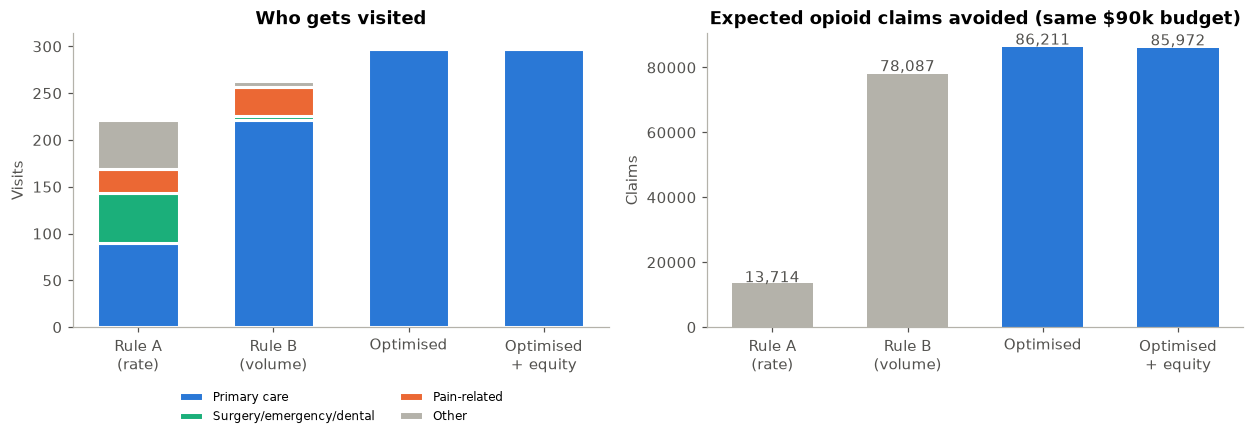

In [53]:
names = list(idx)
mix = pd.DataFrame({n: cand.loc[idx[n], "group"].value_counts() for n in names}).fillna(0)
order = ["Primary care", "Surgery/emergency/dental", "Pain-related", "Other"]
mix = mix.reindex([o for o in order if o in mix.index])
colors = {"Primary care": BLUE, "Surgery/emergency/dental": "#1baf7a", "Pain-related": ORANGE, "Other": GREY}
labels = ["Rule A\n(rate)", "Rule B\n(volume)", "Optimised", "Optimised\n+ equity"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
bottom = np.zeros(len(names))
for g in mix.index:
    axes[0].bar(labels, mix.loc[g].values, bottom=bottom, color=colors[g], label=g, width=0.6, edgecolor="white", linewidth=2)
    bottom += mix.loc[g].values
axes[0].set(title="Who gets visited", ylabel="Visits")
axes[0].legend(frameon=False, fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
vals = plans["expected_claims_avoided"].values
axes[1].bar(labels, vals, color=[GREY, GREY, BLUE, BLUE], width=0.6)
for i, v in enumerate(vals): axes[1].text(i, v*1.01, f"{v:,.0f}", ha="center", color=INK)
axes[1].set(title="Expected opioid claims avoided (same $90k budget)", ylabel="Claims")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/07_optimization.png", bbox_inches="tight"); plt.show()

In [54]:
v = plans["expected_claims_avoided"]
uplift_vs_volume = v["Optimised (PuLP)"] / v["Rule B: highest volume"] - 1
uplift_vs_rate = v["Optimised (PuLP)"] / v["Rule A: highest rate"]
price_of_equity = 1 - v["Optimised + equity rule"] / v["Optimised (PuLP)"]
print(f"Optimised vs 'highest volume' rule: {uplift_vs_volume:+.1%} more claims avoided for the same money")
print(f"Optimised vs 'highest rate' rule: {uplift_vs_rate:.1f}x the impact")
print(f"Cost of the equity rule (West ≥ 25% of visits): {price_of_equity:.1%} of impact given up")
cand.loc[idx["Optimised (PuLP)"], ["npi", "specialty", "division", "zip3", "opioid_claims", "opioid_rate", "cost", "expected_reduction"]] \
    .sort_values("expected_reduction", ascending=False).to_csv(f"{RES_DIR}/tn_visit_plan.csv", index=False)

Optimised vs 'highest volume' rule: +10.4% more claims avoided for the same money
Optimised vs 'highest rate' rule: 6.3x the impact
Cost of the equity rule (West ≥ 25% of visits): 0.3% of impact given up


**What this shows:**
- **Targeting by opioid *rate* is a trap.** Many high-rate doctors write few prescriptions in total (e.g. a surgeon
  with 30 claims, 25 of them opioids). Visiting them barely moves the state total.
- **Optimisation beats the "biggest prescriber" rule** because it balances volume, responsiveness, cost and regional
  capacity at the same time, so it fits more high-impact, lower-cost visits into the same budget.
- **Equity has a measurable price.** Forcing a quarter of visits into West Tennessee costs a small share of impact.
  That is a policy decision for the client, and the model makes the trade-off explicit instead of hidden.
- *Watch-out:* the optimised plan is almost all primary care because, under my assumptions, those visits are both the
  cheapest and the most effective. A client would rightly challenge that, which is why the sensitivity check below matters
  and why a pilot to measure real responsiveness is the first recommended next step.
- *Honest note:* a smart ranking (expected reduction ÷ cost) gets close to the optimum here. PuLP's value is that it
  **guarantees** the best answer and keeps working when more rules are added (equity, minimum coverage, scheduling).

### 5.1 Sensitivity check: what if the responsiveness assumptions are wrong?
A consultant should never present a result that hinges on one guess. I re-run the model with primary-care
responsiveness from 6% to 18% and check whether optimisation still beats the "highest volume" rule.

In [55]:
base_resp, sens = RESP.copy(), []
for pc in [0.06, 0.09, 0.12, 0.15, 0.18]:
    RESP["Primary care"] = pc; set_responsiveness()
    opt_val = cand.loc[optimise(), "expected_reduction"].sum()
    vol_val = cand.loc[rule_of_thumb("opioid_claims"), "expected_reduction"].sum()
    sens.append({"primary_care_responsiveness": pc, "optimised": round(opt_val), "rule_b_volume": round(vol_val)})
RESP = base_resp; set_responsiveness()
sens = pd.DataFrame(sens); sens["uplift_vs_rule_b"] = (sens["optimised"] / sens["rule_b_volume"] - 1).round(3)
sens

,primary_care_responsiveness,optimised,rule_b_volume,uplift_vs_rule_b
0,0.06,44216,42399,0.043
1,0.09,64960,60243,0.078
2,0.12,86211,78087,0.104
3,0.15,107580,95932,0.121
4,0.18,128974,113776,0.134


## 6. Save results for the LLM summary step
All key numbers go into one JSON file. `src/llm_summary.py` sends this file to an LLM to draft an executive brief,
then **automatically checks every number in the LLM's text against this file** to catch hallucinations.

In [56]:
summary = {
    "data": {"source": "CMS Medicare Part D Opioid Prescriber Summary File", "main_year": 2016,
             "prescribers_analysed_2016": int(len(df)), "suppression_note": "opioid counts of 1-10 are suppressed by CMS"},
    "concentration": {k: round(v*100, 1) for k, v in pareto.items()},
    "trend": {int(r.year): round(r.aggregate_rate, 2) for r in trend.itertuples()},
    "top_specialties_by_volume": {s: {"share_of_opioid_claims_pct": round(r.share_of_all_opioid_claims*100, 1),
                                      "median_rate_pct": round(r.median_rate, 1)} for s, r in top_spec.head(6).iterrows()},
    "tests": {
        "specialty_kruskal": {"p_value": float(p_kw), "epsilon_squared": round(eps2, 3)},
        "np_vs_pcp_mannwhitney": {"p_value": float(p_mw), "rank_biserial_r": round(r_rb, 3),
                                  "median_np": round(float(np.median(np_rates)), 2), "median_pcp": round(float(np.median(pcp_rates)), 2),
                                  "median_diff_ci95": [round(ci_lo, 2), round(ci_hi, 2)]},
        "region_chisquare": {"p_value": float(p_chi), "cramers_v": round(cramers_v, 3),
                             "high_prescriber_threshold_pct": round(p90, 1),
                             "pct_high_by_region": (region_share*100).round(1).to_dict()},
        "paired_2013_2016_wilcoxon": {"p_value": float(p_w), "doctors_matched": int(len(paired)),
                                      "mean_change_pts": round(mean_chg, 2), "ci95": [round(t_lo, 2), round(t_hi, 2)],
                                      "pct_doctors_reduced": round(share_down*100, 1)},
    },
    "regression": {"r_squared": round(model.rsquared, 3), "n": int(model.nobs), "max_vif": round(vif.max(), 2),
                   "specialty_effects_vs_family_practice_pts": c["coef"].round(1).rename(lambda s: s.replace("Specialty: ", "")).to_dict()},
    "optimization": {"state": STATE, "budget_usd": BUDGET, "capacity": CAPACITY,
                     "plans": plans.reset_index().to_dict(orient="records"),
                     "uplift_optimised_vs_volume_rule_pct": round(uplift_vs_volume*100, 1),
                     "optimised_vs_rate_rule_multiple": round(uplift_vs_rate, 1),
                     "price_of_equity_pct": round(price_of_equity*100, 1),
                     "sensitivity_uplift_range_pct": [round(sens.uplift_vs_rule_b.min()*100, 1), round(sens.uplift_vs_rule_b.max()*100, 1)]},
}
with open(f"{RES_DIR}/summary.json", "w") as f: json.dump(summary, f, indent=2, default=float)
print(json.dumps(summary["optimization"], indent=2, default=float)[:1500])

{
  "state": "TN",
  "budget_usd": 90000,
  "capacity": {
    "East": 120,
    "Middle": 120,
    "West": 80
  },
  "plans": [
    {
      "plan": "Rule A: highest rate",
      "visits": 221,
      "spend_usd": 89850,
      "expected_claims_avoided": 13714,
      "pct_of_state_opioid_claims": 0.48,
      "west_share_of_visits": 0.195,
      "primary_care_share": 0.407
    },
    {
      "plan": "Rule B: highest volume",
      "visits": 263,
      "spend_usd": 89850,
      "expected_claims_avoided": 78087,
      "pct_of_state_opioid_claims": 2.72,
      "west_share_of_visits": 0.16,
      "primary_care_share": 0.84
    },
    {
      "plan": "Optimised (PuLP)",
      "visits": 299,
      "spend_usd": 90000,
      "expected_claims_avoided": 86211,
      "pct_of_state_opioid_claims": 3.01,
      "west_share_of_visits": 0.201,
      "primary_care_share": 0.993
    },
    {
      "plan": "Optimised + equity rule",
      "visits": 299,
      "spend_usd": 90000,
      "expected_claims_avoided

## 7. Conclusions & recommendations
*(The numbers below are filled from this run's output; see `results/summary.json`.)*

1. **Opioid prescribing is highly concentrated.** A small fraction of prescribers accounts for most opioid claims,
   so targeted outreach is far more efficient than broad campaigns.
2. **Specialty is the dominant driver; region matters much less.** Kruskal–Wallis shows a large specialty effect,
   while the chi-square test shows only a small regional effect. The regression confirms this after controlling for practice size.
3. **Prescribing is falling, within the same doctors.** The paired test shows the decline is not just a change in who
   is in the data; individual doctors reduced their rates between 2013 and 2016.
4. **Smarter targeting beats rules of thumb.** Targeting by opioid *rate* wastes most of the budget on low-volume
   doctors. The optimised plan beats "visit the biggest prescribers" for the same \$90k, and the advantage holds across
   the sensitivity range. An equity rule for West Tennessee costs only a small, measurable share of impact.

**Limitations:** suppressed low counts; Medicare covers mainly patients aged 65+; claims count prescriptions, not doses
(no morphine-milligram equivalents); responsiveness values are assumptions; regression shows association, not causation.

**Next steps:** pilot the visits in a few areas and measure actual responsiveness (ideally as a randomised A/B test),
add dose (MME) data, and try a two-part or beta regression model.